# Сравнение вариантов `linkage` в `AgglomerativeClustering`

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import (make_blobs, make_moons, make_circles,
                              load_iris, load_wine, load_breast_cancer, load_digits)
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 90

SEED = 4
LINKAGES = ["ward", "complete", "average", "single"]
COLORS = np.array(["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd",
                   "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"])

In [2]:
def fit_agglo(X, n_clusters, linkage, metric="euclidean"):
    model = AgglomerativeClustering(n_clusters=n_clusters, linkage=linkage, metric=metric)
    t0 = time.perf_counter()
    labels = model.fit_predict(X)
    return labels, time.perf_counter() - t0

## 1. датасеты

1) Три хорошо разделённых облака
2) Облака с сильно разной дисперсией
3) Облака с разным числом точек (400 / 150 / 50)
4) Вытянутые облака
5) два невыпуклых кластера
6) Вложенные окружности
7) Облака + 5 % равномерного шума

Ко всем признакам применяется `StandardScaler`.

In [3]:
def make_datasets(n=600, seed=SEED):
    rng = np.random.RandomState(seed)
    data = {}

    X, y = make_blobs(n_samples=n, centers=3, cluster_std=1.0, random_state=seed)
    data["Blobs"] = (X, y, 3)

    X, y = make_blobs(n_samples=n, centers=3, cluster_std=[1.0, 2.5, 0.5], random_state=170)
    data["Variance"] = (X, y, 3)

    X, y = make_blobs(n_samples=[400, 150, 50], centers=[[0, 0], [5, 5], [0, 6]],
                      cluster_std=1.0, random_state=seed)
    data["Unequal sizes"] = (X, y, 3)

    X, y = make_blobs(n_samples=n, centers=3, random_state=170)
    X = X @ np.array([[0.6, -0.6], [-0.4, 0.8]])
    data["Stretched"] = (X, y, 3)

    X, y = make_moons(n_samples=n, noise=0.05, random_state=seed)
    data["Nonconvex"] = (X, y, 2)

    X, y = make_circles(n_samples=n, factor=0.5, noise=0.05, random_state=seed)
    data["Circles"] = (X, y, 2)

    X, y = make_blobs(n_samples=n, centers=3, cluster_std=1.0, random_state=seed)
    n_out = int(0.05 * n)
    lo, hi = X.min(axis=0) - 3, X.max(axis=0) + 3
    X_out = rng.uniform(lo, hi, size=(n_out, 2))
    X = np.vstack([X, X_out])
    y = np.concatenate([y, -np.ones(n_out, dtype=int)])
    data["Blobs + outliers"] = (X, y, 3)

    return {name: (StandardScaler().fit_transform(X), y, k) for name, (X, y, k) in data.items()}


datasets = make_datasets()
pd.DataFrame({name: {"n_samples": len(X), "n_clusters": k} for name, (X, y, k) in datasets.items()}).T

,n_samples,n_clusters
Blobs,600,3
Variance,600,3
Unequal sizes,600,3
Stretched,600,3
Nonconvex,600,2
Circles,600,2
Blobs + outliers,630,3


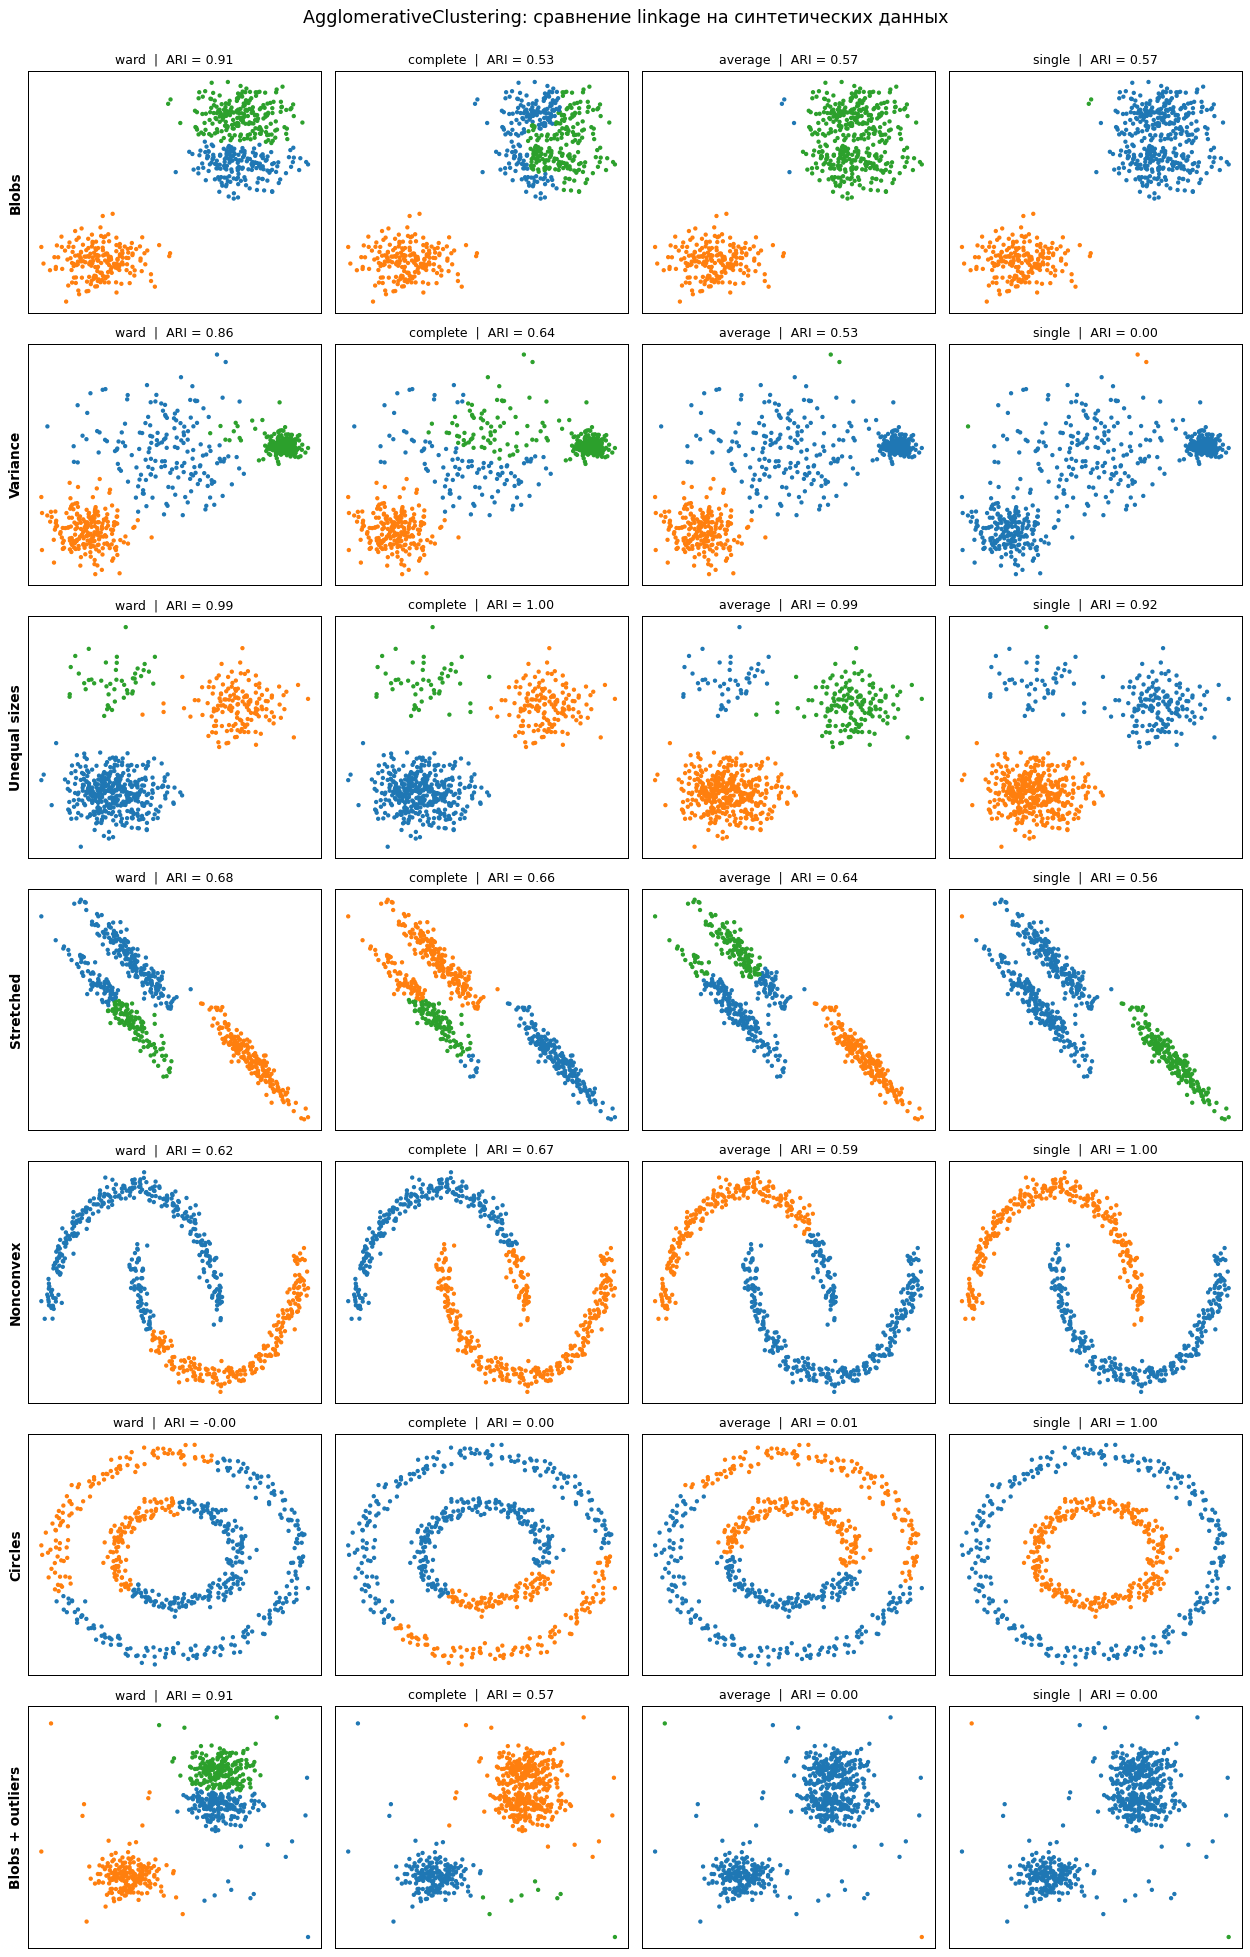

In [4]:
rows = []
results_labels = {}

for ds_name, (X, y, k) in datasets.items():
    mask = y >= 0 
    for link in LINKAGES:
        labels, t = fit_agglo(X, k, link)
        results_labels[(ds_name, link)] = labels
        rows.append({"dataset": ds_name, "linkage": link, "time_s": t,
                     "ARI": adjusted_rand_score(y[mask], labels[mask])})

synth_res = pd.DataFrame(rows)

fig, axes = plt.subplots(len(datasets), len(LINKAGES), figsize=(14, 3.1 * len(datasets)))
for i, (ds_name, (X, y, k)) in enumerate(datasets.items()):
    for j, link in enumerate(LINKAGES):
        ax = axes[i, j]
        labels = results_labels[(ds_name, link)]
        ari = synth_res.query("dataset == @ds_name and linkage == @link")["ARI"].item()
        ax.scatter(X[:, 0], X[:, 1], s=6, c=COLORS[labels % len(COLORS)])
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{link}  |  ARI = {ari:.2f}", fontsize=10)
        if j == 0:
            ax.set_ylabel(ds_name, fontsize=11, fontweight="bold")
plt.suptitle("AgglomerativeClustering: сравнение linkage на синтетических данных", fontsize=14, y=1.0)
plt.tight_layout()
plt.show()

In [5]:
ari_table = synth_res.pivot(index="dataset", columns="linkage", values="ARI")[LINKAGES].loc[list(datasets)]

print("ARI:")
display(ari_table.style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1, axis=None).format("{:.3f}"))

ARI:


linkage,ward,complete,average,single
dataset,,,,
Blobs,0.909,0.530,0.568,0.569
Variance,0.863,0.637,0.534,0.000
Unequal sizes,0.991,1.000,0.991,0.917
Stretched,0.681,0.657,0.644,0.564
Nonconvex,0.618,0.672,0.592,1.000
Circles,-0.001,0.004,0.009,1.000
Blobs + outliers,0.909,0.571,0.000,0.000


In [6]:
summary = pd.DataFrame({
    "mean ARI": ari_table.mean(),
    "median ARI": ari_table.median(),
    "best ARI": ari_table.eq(ari_table.max(axis=1), axis=0).sum(),
}).loc[LINKAGES].round(3)
summary

,mean ARI,median ARI,best ARI
linkage,,,
ward,0.710,0.863,4
complete,0.581,0.637,1
average,0.477,0.568,0
single,0.579,0.569,2


- **Blobs** - два облака из трёх почти касаются друг друга. Разделить их смог только `ward`. `complete` режет склеенную пару не по границе, а `average` и `single` объединяют два облака в один кластер и тратят третий на одиночную точку.
- **Variance** - лучше всех `ward`. `complete` и `average` режут широкое облако или объединяют его с соседним, а `single` склеивает почти всё в один кластер.
- **Unequal sizes** - кластеры хорошо разделены, и все справляются. `single` чуть хуже.
- **Stretched** - идеального решения нет ни у кого.
- **Nonconvex / Circles** - выигрывает только `single`. Остальные режут данные прямой линией.
- **Blobs + outliers** - `ward` выбросы не мешают. `complete` отдаёт один кластер выбросам, а `average` и `single` полностью ломаются.

В среднем лучший `ward`, но невыпуклые кластеры находит только `single`.

## 2. Устойчивость к шуму и выбросам

`make_moons` с увеличивающимся гауссовым шумом, `noise` от 0.02 до 0.20.

Три гауссовых облака с долей равномерных выбросов от 0 до 10 %. ARI считаем только по настоящим точкам.

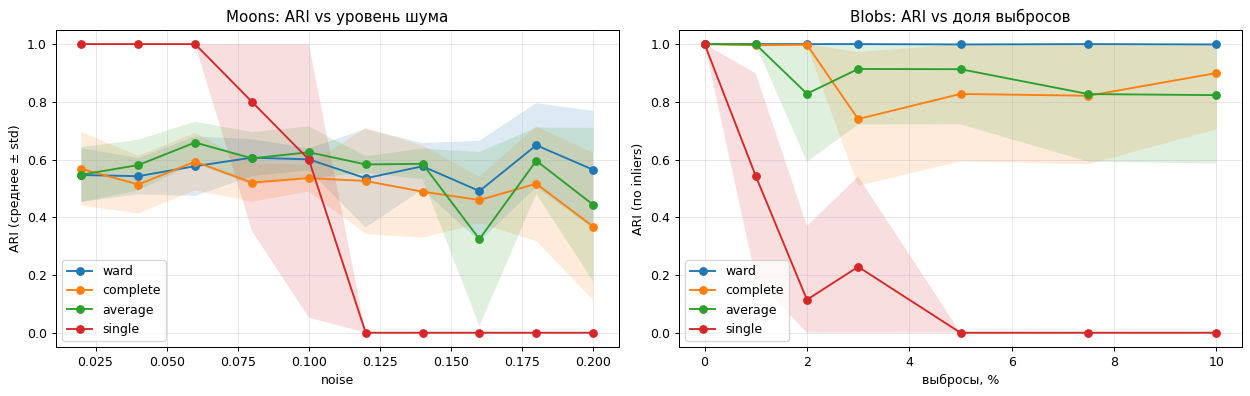

linkage,ward,complete,average,single
noise,,,,
0.02,0.546,0.568,0.548,1.0
0.04,0.542,0.513,0.581,1.0
0.06,0.577,0.593,0.659,1.0
0.08,0.607,0.520,0.604,0.8
0.10,0.601,0.536,0.625,0.6
0.12,0.535,0.526,0.583,0.0
0.14,0.577,0.489,0.585,0.0
0.16,0.491,0.460,0.324,0.0
0.18,0.650,0.516,0.596,0.0


linkage,ward,complete,average,single
outliers,,,,
0.000,1.000,1.000,1.000,1.000
0.010,1.000,0.996,0.999,0.543
0.020,1.000,0.998,0.828,0.114
0.030,1.000,0.740,0.914,0.228
0.050,0.999,0.827,0.913,0.000
0.075,1.000,0.821,0.827,0.000
0.100,0.999,0.900,0.823,0.000


In [7]:
noise_levels = np.round(np.linspace(0.02, 0.20, 10), 3)
seeds = range(5)
rows = []
for noise in noise_levels:
    for s in seeds:
        X, y = make_moons(n_samples=500, noise=noise, random_state=s)
        X = StandardScaler().fit_transform(X)
        for link in LINKAGES:
            labels, _ = fit_agglo(X, 2, link)
            rows.append({"noise": noise, "seed": s, "linkage": link,
                         "ARI": adjusted_rand_score(y, labels)})
noise_res = pd.DataFrame(rows)

out_fracs = [0.0, 0.01, 0.02, 0.03, 0.05, 0.075, 0.10]
rows = []
for frac in out_fracs:
    for s in seeds:
        rng = np.random.RandomState(s)
        X, y = make_blobs(n_samples=500, centers=[[-5, 0], [5, 0], [0, 8]],
                          cluster_std=1.0, random_state=s)
        n_out = int(frac * len(X))
        if n_out:
            lo, hi = X.min(axis=0) - 3, X.max(axis=0) + 3
            X = np.vstack([X, rng.uniform(lo, hi, size=(n_out, 2))])
            y = np.concatenate([y, -np.ones(n_out, dtype=int)])
        X = StandardScaler().fit_transform(X)
        mask = y >= 0
        for link in LINKAGES:
            labels, _ = fit_agglo(X, 3, link)
            rows.append({"outliers": frac, "seed": s, "linkage": link,
                         "ARI": adjusted_rand_score(y[mask], labels[mask])})
outlier_res = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for link in LINKAGES:
    g = noise_res[noise_res.linkage == link].groupby("noise")["ARI"]
    m, sd = g.mean(), g.std()
    axes[0].plot(m.index, m.values, marker="o", label=link)
    axes[0].fill_between(m.index, (m - sd).clip(0, 1), (m + sd).clip(0, 1), alpha=0.15)

    g = outlier_res[outlier_res.linkage == link].groupby("outliers")["ARI"]
    m, sd = g.mean(), g.std()
    axes[1].plot(m.index * 100, m.values, marker="o", label=link)
    axes[1].fill_between(m.index * 100, (m - sd).clip(0, 1), (m + sd).clip(0, 1), alpha=0.15)

axes[0].set(title="Moons: ARI vs уровень шума", xlabel="noise", ylabel="ARI (среднее ± std)")
axes[1].set(title="Blobs: ARI vs доля выбросов", xlabel="выбросы, %", ylabel="ARI (по inliers)")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3); ax.set_ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

display(noise_res.pivot_table(index="noise", columns="linkage", values="ARI")[LINKAGES].round(3))
display(outlier_res.pivot_table(index="outliers", columns="linkage", values="ARI")[LINKAGES].round(3))

- **Шум** - `single` идеален при малом шуме, остальные с самого начала режут прямой, и шум влияет на них гораздо меньше.
- **Выбросы** - `ward` почти не замечает. `complete` и `average` начинают ошибаться с 2–3 %, а `single` ломается при 1 %.

Итого по устойчивости: `ward` > `complete` ≈ `average` ≫ `single`.

## 3. Время работы

Замерим время `fit` на трёх гауссовых облаках при разном размере выборки (среднее по 3 запускам)

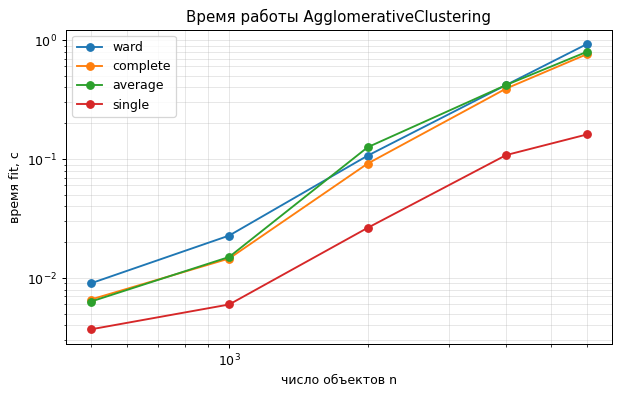

linkage,ward,complete,average,single
n,,,,
500,0.009,0.007,0.006,0.004
1000,0.023,0.015,0.015,0.006
2000,0.107,0.092,0.126,0.026
4000,0.420,0.392,0.419,0.108
6000,0.928,0.763,0.799,0.161


In [8]:
sizes_n = [500, 1000, 2000, 4000, 6000]
rows = []
for n in sizes_n:
    X, _ = make_blobs(n_samples=n, centers=3, random_state=SEED)
    for link in LINKAGES:
        ts = [fit_agglo(X, 3, link)[1] for _ in range(3)]
        rows.append({"n": n, "linkage": link, "time_s": np.mean(ts)})
time_res = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4.5))
for link in LINKAGES:
    d = time_res[time_res.linkage == link]
    ax.plot(d.n, d.time_s, marker="o", label=link)
ax.set(xscale="log", yscale="log", xlabel="число объектов n", ylabel="время fit, с",
       title="Время работы AgglomerativeClustering")
ax.grid(alpha=0.3, which="both"); ax.legend()
plt.tight_layout()
plt.show()

time_res.pivot(index="n", columns="linkage", values="time_s")[LINKAGES].round(4)

- `single` быстрее остальных примерно в 4–6 раз.
- `ward`, `complete` и `average` работают примерно одинаково.

## 4. Реальные датасеты

Возьмём четыре встроенных датасета `sklearn` с известными классами: **Iris**, **Wine**, **Breast cancer** и **Digits**. Признаки стандартизируем, число кластеров равно числу классов. Кроме ARI смотрим долю объектов в самом большом кластере.

,n_samples,n_features,n_clusters
Iris,150,4,3
Wine,178,13,3
Breast cancer,569,30,2
Digits,1797,64,10


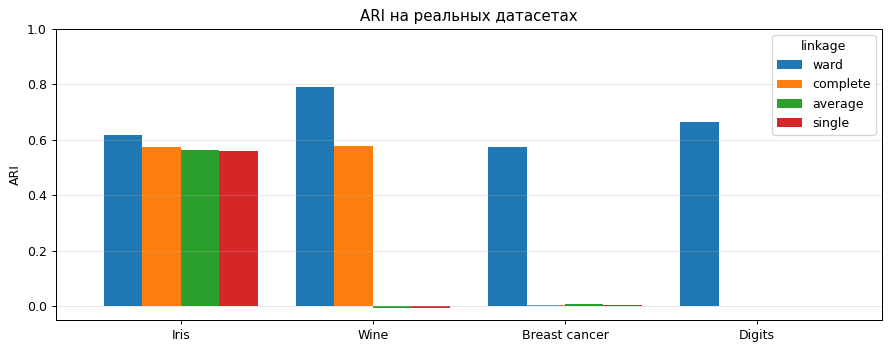

ARI:


linkage,ward,complete,average,single
dataset,,,,
Iris,0.615,0.573,0.562,0.558
Wine,0.790,0.577,-0.005,-0.007
Breast cancer,0.575,0.005,0.007,0.005
Digits,0.664,0.000,0.000,0.000


Доля объектов в самом большом кластере, %:


linkage,ward,complete,average,single
dataset,,,,
Iris,47,51,65,67
Wine,36,39,98,98
Breast cancer,68,100,99,100
Digits,22,97,99,99


In [9]:
def load_real_datasets():
    loaders = {"Iris": load_iris, "Wine": load_wine,
               "Breast cancer": load_breast_cancer, "Digits": load_digits}
    data = {}
    for name, loader in loaders.items():
        X, y = loader(return_X_y=True)
        data[name] = (StandardScaler().fit_transform(X), y, len(np.unique(y)))
    return data


real_datasets = load_real_datasets()
display(pd.DataFrame({name: {"n_samples": X.shape[0], "n_features": X.shape[1], "n_clusters": k}
                      for name, (X, y, k) in real_datasets.items()}).T)

rows = []
for ds_name, (X, y, k) in real_datasets.items():
    for link in LINKAGES:
        labels, t = fit_agglo(X, k, link)
        sizes = np.sort(np.bincount(labels))[::-1]
        rows.append({"dataset": ds_name, "linkage": link, "time_s": t, "ARI": adjusted_rand_score(y, labels),
                     "largest, %": 100 * sizes[0] / len(labels),
                     "sizes": ", ".join(map(str, sizes))})
real_res = pd.DataFrame(rows)


def real_pivot(col):
    return real_res.pivot(index="dataset", columns="linkage", values=col)[LINKAGES].loc[list(real_datasets)]


real_ari = real_pivot("ARI")

fig, ax = plt.subplots(figsize=(10, 4))
real_ari.plot.bar(ax=ax, rot=0, width=0.8)
ax.set(title="ARI на реальных датасетах", xlabel="", ylabel="ARI", ylim=(-0.05, 1))
ax.grid(alpha=0.3, axis="y"); ax.legend(title="linkage")
plt.tight_layout()
plt.show()

print("ARI:")
display(real_ari.style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1, axis=None).format("{:.3f}"))
print("Доля объектов в самом большом кластере, %:")
display(real_pivot("largest, %").style.background_gradient(cmap="Reds", vmin=0, vmax=100, axis=None).format("{:.0f}"))

- **Iris** - все стратегии примерно одинаковые.
- **Wine, Breast cancer, Digits** - `average` и `single` ломаются.

Лучший везде - `ward`.

## 5. Итоги

In [10]:
n_max = max(sizes_n)
overall = pd.DataFrame({
    "mean ARI (синтетика)": ari_table.mean(),
    "побед (синтетика, из 7)": ari_table.eq(ari_table.max(axis=1), axis=0).sum(),
    "mean ARI (реальные)": real_ari.mean(),
    "побед (реальные, из 4)": real_ari.eq(real_ari.max(axis=1), axis=0).sum(),
    "ARI при 5 % выбросов": outlier_res[outlier_res.outliers == 0.05].groupby("linkage")["ARI"].mean(),
    f"время при n = {n_max}, с": time_res[time_res.n == n_max].set_index("linkage")["time_s"],
}).loc[LINKAGES]
overall.round(3)

,mean ARI (синтетика),"побед (синтетика, из 7)",mean ARI (реальные),"побед (реальные, из 4)",ARI при 5 % выбросов,"время при n = 6000, с"
linkage,,,,,,
ward,0.710,4,0.661,4,0.999,0.929
complete,0.581,1,0.289,0,0.827,0.763
average,0.477,0,0.141,0,0.913,0.799
single,0.579,2,0.139,0,0.000,0.161
